# Laboratory Exercise (Model Inference on Custom Dataset)

## Step 1 — Choose and understand the dataset

I recommend the Oxford-IIIT Pet Dataset, available through torchvision. It contains images of cats and dogs, so we can automatically download the data instead of manually collecting and sorting hundreds of images. We'll use its binary cat-versus-dog labels.

## Step 2 — Install and import the libraries

In [ ]:
!pip install -q torch torchvision scikit-learn pandas matplotlib seaborn

In [ ]:
import os
import random
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
print("PyTorch version:", torch.__version__)

Using device: cuda
PyTorch version: 2.11.0+cu130


This cell imports the libraries and sets a random seed to help make the experiment reproducible. A GPU is helpful because we'll train five models.

## Step 3 — Download and inspect the dataset

In [ ]:
data_root = "./data"

trainval_base = datasets.OxfordIIITPet(
    root=data_root,
    split="trainval",
    target_types="binary-category",
    download=True
)

test_base = datasets.OxfordIIITPet(
    root=data_root,
    split="test",
    target_types="binary-category",
    download=True
)

print("Training/validation images:", len(trainval_base))
print("Testing images:", len(test_base))

100%|██████████| 792M/792M [00:37<00:00, 20.9MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 9.50MB/s]


Training/validation images: 3680
Testing images: 3669


The official dataset provides separate trainval and test splits. We'll divide trainval into training and validation subsets, while keeping the test data separate until final evaluation.

Image type: <class 'PIL.Image.Image'>
Image size: (394, 500)
Original binary label: 0


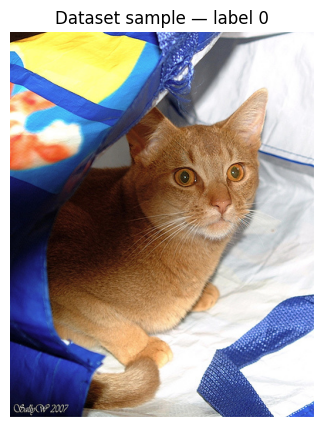

In [ ]:
image, label = trainval_base[0]

print("Image type:", type(image))
print("Image size:", image.size)
print("Original binary label:", label)

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(f"Dataset sample — label {label}")
plt.axis("off")
plt.show()

The original binary labels are typically 1 for cats and 2 for dogs in torchvision's implementation. We'll convert them to 0 and 1 in our custom dataset so the model outputs correspond to cat and dog.

## Step 4 — Create a custom PyTorch Dataset class

In [ ]:
class CustomDataset(Dataset):
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __getitem__(self, idx):
        image, label = self.dataset[idx]

        # Keep the existing binary labels: 0 = cat, 1 = dog
        label = int(label)

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

    def __len__(self):
        return len(self.dataset)

- __init__() stores the underlying dataset and any image transformations.

- __getitem__() loads an image and its label, transforms the image, and returns the image tensor and numeric label.

- __len__() returns the total number of images.

- Labels become 0 = cat and 1 = dog.

## Step 5 — Split the training data

In [ ]:
train_size = int(0.8 * len(trainval_base))
val_size = len(trainval_base) - train_size

train_subset, val_subset = random_split(
    trainval_base,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Test samples:", len(test_base))

Training samples: 2944
Validation samples: 736
Test samples: 3669


We'll use 80% of the training/validation split for training and 20% for validation. The separate test set will be used for the final model comparison.

## Step 6 — Create DataLoaders

In [ ]:
def make_transforms(weights):
    preprocess = weights.transforms()

    size = preprocess.crop_size
    if isinstance(size, (tuple, list)):
        size = size[0]

    mean = preprocess.mean
    std = preprocess.std

    train_transform = transforms.Compose([
        transforms.Resize((size, size)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std)
    ])

    eval_transform = preprocess

    return train_transform, eval_transform

In [ ]:
def make_loaders(weights, batch_size=32):
    train_transform, eval_transform = make_transforms(weights)

    train_dataset = CustomDataset(
        train_subset, transform=train_transform
    )
    val_dataset = CustomDataset(
        val_subset, transform=eval_transform
    )
    test_dataset = CustomDataset(
        test_base, transform=eval_transform
    )

    generator = torch.Generator().manual_seed(SEED)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2,
        pin_memory=torch.cuda.is_available(),
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    return train_loader, val_loader, test_loader

In [ ]:
weights = models.ResNet50_Weights.DEFAULT

train_loader, val_loader, test_loader = make_loaders(weights)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels in batch:", labels[:10].tolist())

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Labels in batch: [0, 1, 0, 1, 1, 1, 1, 0, 1, 1]


## Step 7 — Load the five pre-trained models

We will keep the pre-trained feature extractors frozen and train only the final classification layers. This makes the comparison more manageable and reduces training time.

In [ ]:
def build_model(model_name):
    if model_name == "ResNet50":
        weights = models.ResNet50_Weights.DEFAULT
        model = models.resnet50(weights=weights)
        in_features = model.fc.in_features
        model.fc = nn.Linear(in_features, 2)

    elif model_name == "MobileNetV3-Large":
        weights = models.MobileNet_V3_Large_Weights.DEFAULT
        model = models.mobilenet_v3_large(weights=weights)
        in_features = model.classifier[3].in_features
        model.classifier[3] = nn.Linear(in_features, 2)

    elif model_name == "EfficientNet-B0":
        weights = models.EfficientNet_B0_Weights.DEFAULT
        model = models.efficientnet_b0(weights=weights)
        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_features, 2)

    elif model_name == "DenseNet121":
        weights = models.DenseNet121_Weights.DEFAULT
        model = models.densenet121(weights=weights)
        in_features = model.classifier.in_features
        model.classifier = nn.Linear(in_features, 2)

    elif model_name == "VGG16":
        weights = models.VGG16_Weights.DEFAULT
        model = models.vgg16(weights=weights)
        in_features = model.classifier[6].in_features
        model.classifier[6] = nn.Linear(in_features, 2)

    else:
        raise ValueError(f"Unknown model: {model_name}")

    # Freeze the pre-trained feature extractor
    for param in model.parameters():
        param.requires_grad = False

    # Train only the newly replaced classification layer
    if model_name == "ResNet50":
        for param in model.fc.parameters():
            param.requires_grad = True
    elif model_name == "MobileNetV3-Large":
        for param in model.classifier[3].parameters():
            param.requires_grad = True
    elif model_name == "EfficientNet-B0":
        for param in model.classifier[1].parameters():
            param.requires_grad = True
    elif model_name == "DenseNet121":
        for param in model.classifier.parameters():
            param.requires_grad = True
    elif model_name == "VGG16":
        for param in model.classifier[6].parameters():
            param.requires_grad = True

    return model, weights

In [ ]:
model, weights = build_model("ResNet50")

print(model.__class__.__name__)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters()
          if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 211MB/s]


ResNet
Trainable parameters: 4098


## Step 8 — Define the training and validation functions

In [ ]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None
    model.train() if is_training else model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.set_grad_enabled(is_training):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            if is_training:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if is_training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * labels.size(0)

            preds = outputs.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_labels, all_preds)

    return avg_loss, accuracy

In [ ]:
def train_model(model, train_loader, val_loader, epochs=3):
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        [p for p in model.parameters() if p.requires_grad],
        lr=0.001
    )

    best_val_accuracy = -1
    best_state = copy.deepcopy(model.state_dict())
    history = []

    for epoch in range(epochs):
        train_loss, train_acc = run_epoch(
            model, train_loader, criterion, optimizer
        )

        val_loss, val_acc = run_epoch(
            model, val_loader, criterion
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc
        })

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Train accuracy: {train_acc:.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Val accuracy: {val_acc:.4f}"
        )

        if val_acc > best_val_accuracy:
            best_val_accuracy = val_acc
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

The function trains the classification layer, measures performance on the validation set after each epoch, and retains the model state with the best validation accuracy. The test set is not used for choosing the best epoch.

## Step 9 — Evaluate the five models

This step may take a while, particularly if you use a CPU. Three epochs per model is a reasonable initial experiment; you can increase the epochs later if needed.

In [ ]:
model_names = [
    "ResNet50",
    "MobileNetV3-Large",
    "EfficientNet-B0",
    "DenseNet121",
    "VGG16"
]

trained_models = {}
histories = {}
results = []
test_predictions = {}

for name in model_names:
    print("\n" + "=" * 60)
    print("Training:", name)
    print("=" * 60)

    model, weights = build_model(name)

    train_loader, val_loader, test_loader = make_loaders(
        weights, batch_size=32
    )

    start_time = time.time()

    model, history = train_model(
        model, train_loader, val_loader, epochs=3
    )

    elapsed = time.time() - start_time

    # Final evaluation on the separate test set
    criterion = nn.CrossEntropyLoss()
    test_loss, test_accuracy = run_epoch(
        model, test_loader, criterion
    )

    # Collect final predictions for all test images
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.numpy().tolist())
            y_pred.extend(predictions.cpu().numpy().tolist())

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "Test Loss": test_loss,
        "Training Time (seconds)": elapsed
    })

    trained_models[name] = model.cpu()
    histories[name] = history
    test_predictions[name] = (y_true, y_pred)

    model.to(device)

    print(f"Test accuracy: {results[-1]['Accuracy']:.4f}")
    print(f"Elapsed time: {elapsed:.1f} seconds")


Training: ResNet50
Epoch 1/3 | Train loss: 0.2079 | Train accuracy: 0.9453 | Val loss: 0.0741 | Val accuracy: 0.9959
Epoch 2/3 | Train loss: 0.0595 | Train accuracy: 0.9888 | Val loss: 0.0436 | Val accuracy: 0.9946
Epoch 3/3 | Train loss: 0.0363 | Train accuracy: 0.9942 | Val loss: 0.0305 | Val accuracy: 0.9959
Test accuracy: 0.9905
Elapsed time: 68.1 seconds

Training: MobileNetV3-Large
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 172MB/s]


Epoch 1/3 | Train loss: 0.2850 | Train accuracy: 0.9147 | Val loss: 0.1404 | Val accuracy: 0.9742
Epoch 2/3 | Train loss: 0.1305 | Train accuracy: 0.9626 | Val loss: 0.0950 | Val accuracy: 0.9755
Epoch 3/3 | Train loss: 0.0945 | Train accuracy: 0.9762 | Val loss: 0.0794 | Val accuracy: 0.9769
Test accuracy: 0.9806
Elapsed time: 58.6 seconds

Training: EfficientNet-B0
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 194MB/s]


Epoch 1/3 | Train loss: 0.3273 | Train accuracy: 0.8882 | Val loss: 0.1794 | Val accuracy: 0.9606
Epoch 2/3 | Train loss: 0.1748 | Train accuracy: 0.9453 | Val loss: 0.1227 | Val accuracy: 0.9715
Epoch 3/3 | Train loss: 0.1365 | Train accuracy: 0.9596 | Val loss: 0.0998 | Val accuracy: 0.9755
Test accuracy: 0.9665
Elapsed time: 57.7 seconds

Training: DenseNet121
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 226MB/s]


Epoch 1/3 | Train loss: 0.2165 | Train accuracy: 0.9307 | Val loss: 0.0706 | Val accuracy: 0.9783
Epoch 2/3 | Train loss: 0.0771 | Train accuracy: 0.9813 | Val loss: 0.0483 | Val accuracy: 0.9918
Epoch 3/3 | Train loss: 0.0564 | Train accuracy: 0.9854 | Val loss: 0.0325 | Val accuracy: 0.9918
Test accuracy: 0.9902
Elapsed time: 64.0 seconds

Training: VGG16
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:06<00:00, 84.1MB/s]


Epoch 1/3 | Train loss: 0.0513 | Train accuracy: 0.9830 | Val loss: 0.0159 | Val accuracy: 0.9959
Epoch 2/3 | Train loss: 0.0206 | Train accuracy: 0.9935 | Val loss: 0.0129 | Val accuracy: 0.9973
Epoch 3/3 | Train loss: 0.0141 | Train accuracy: 0.9959 | Val loss: 0.0130 | Val accuracy: 0.9946
Test accuracy: 0.9959
Elapsed time: 72.0 seconds


## Step 10 — Display the model comparison table

Once all five models finish running, create the comparison table

In [ ]:
results_df = pd.DataFrame(results)

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]

results_df = results_df.sort_values(
    by="F1-score", ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "Test Loss": "{:.4f}",
        "Training Time (seconds)": "{:.1f}"
    })
)

,Model,Accuracy,Precision,Recall,F1-score,Test Loss,Training Time (seconds)
0,VGG16,0.9959,0.9960,0.9980,0.9970,0.0111,72.0
1,ResNet50,0.9905,0.9865,0.9996,0.9930,0.0821,68.1
2,DenseNet121,0.9902,0.9920,0.9936,0.9928,0.0496,64.0
3,MobileNetV3-Large,0.9806,0.9790,0.9928,0.9858,0.0754,58.6
4,EfficientNet-B0,0.9665,0.9628,0.9887,0.9756,0.1142,57.7


Metric | Meaning
--- | ---
Accuracy | Proportion of all test images classified correctly
Precision | Of the images predicted as dogs, the proportion that are dogs
Recall | Of all actual dog images, the proportion correctly identified
F1-score | Harmonic mean of precision and recall

## Step 11 — Visualize the results

A grouped bar chart makes the comparison easier to understand

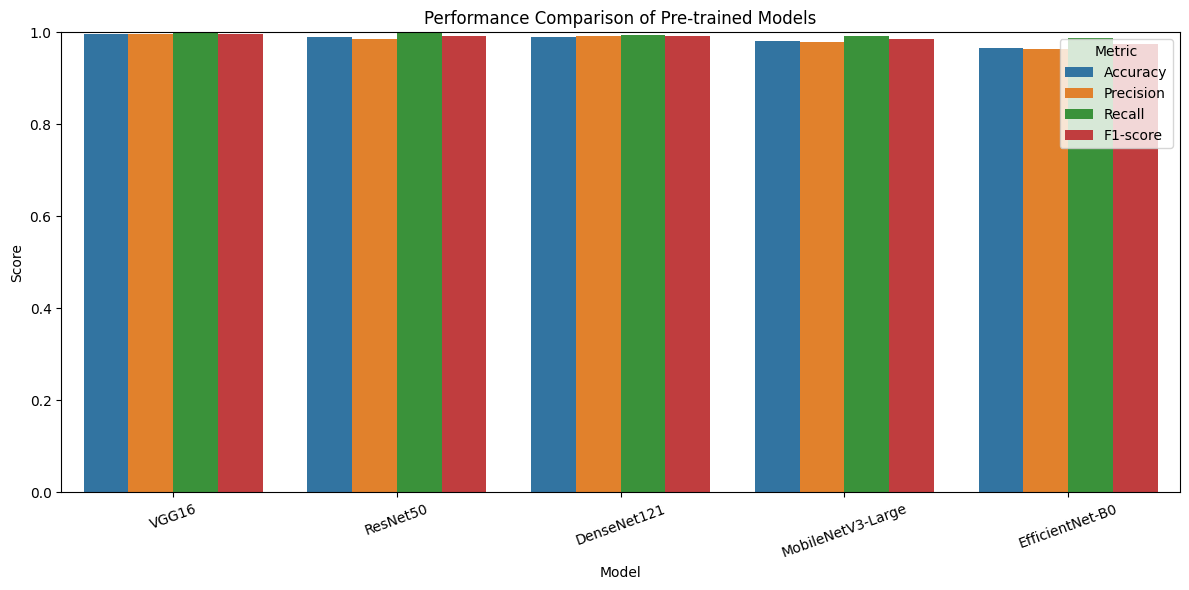

In [ ]:
plot_df = results_df.melt(
    id_vars="Model",
    value_vars=metric_columns,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_df,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Performance Comparison of Pre-trained Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

compare training time

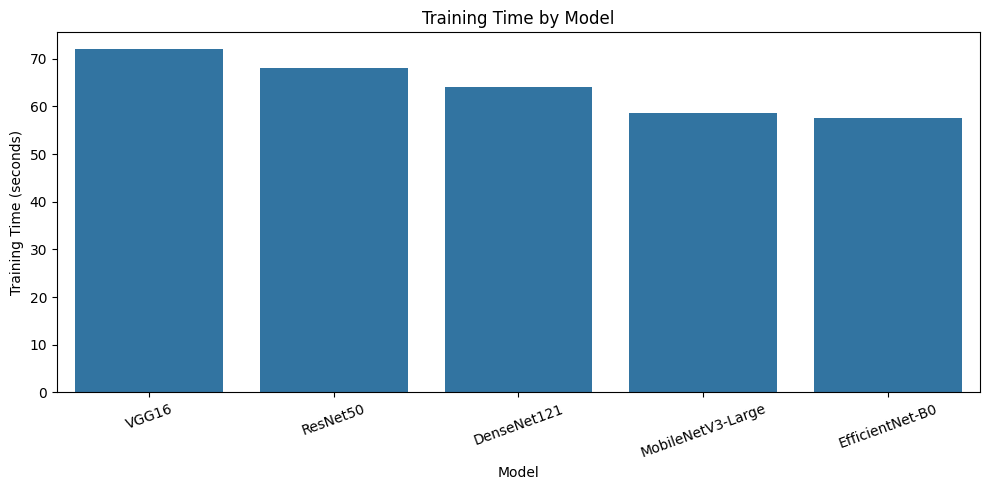

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Training Time (seconds)"
)

plt.title("Training Time by Model")
plt.xlabel("Model")
plt.ylabel("Training Time (seconds)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Step 12 — Generate a confusion matrix

The confusion matrix shows which cats and dogs each model misclassified. Start with the highest-ranked model

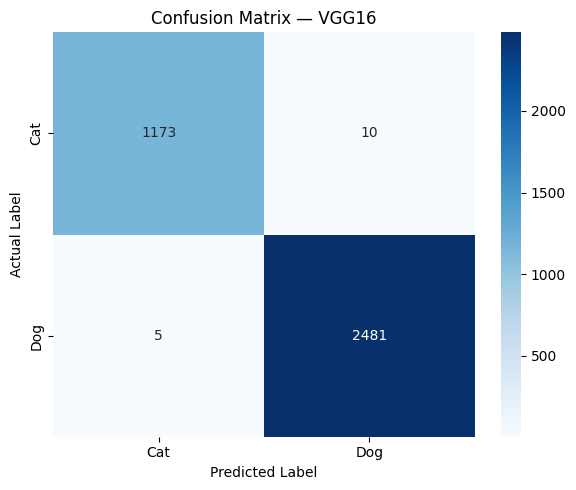

Best model by F1-score: VGG16
              precision    recall  f1-score   support

         Cat       1.00      0.99      0.99      1183
         Dog       1.00      1.00      1.00      2486

    accuracy                           1.00      3669
   macro avg       1.00      0.99      1.00      3669
weighted avg       1.00      1.00      1.00      3669



In [ ]:
best_model_name = results_df.iloc[0]["Model"]

y_true, y_pred = test_predictions[best_model_name]

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Cat", "Dog"],
    yticklabels=["Cat", "Dog"]
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

print("Best model by F1-score:", best_model_name)
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Cat", "Dog"],
        zero_division=0
    )
)

## Step 13 — Analysis of Results
#### 1. Overall performance: VGG16 achieved the highest accuracy of 99.59% and the highest F1-score of 99.70%. This indicates that it provided the strongest overall balance of classification performance among the five evaluated models.

#### 2. Precision and recall: ResNet50 achieved the highest recall of 99.96%, meaning it identified nearly all actual dog images. VGG16 achieved 99.60% precision and 99.80% recall, showing that it performed consistently well across the selected metrics.

#### 3. Model comparison: DenseNet121 achieved 99.02% accuracy and a 99.28% F1-score, placing it close to ResNet50. MobileNetV3-Large achieved 98.06% accuracy, while EfficientNet-B0 achieved 96.65%. Although all five models performed well, their results differed under the same experimental setup.

#### 4. Training efficiency: EfficientNet-B0 had the shortest training time at 57.7 seconds, while VGG16 took 72.0 seconds. This demonstrates a trade-off between computational time and classification performance in this experiment. VGG16 took longer but achieved the best accuracy and F1-score.

#### 5. Model architecture: The differences may be related to each architecture's feature extraction design, complexity, and suitability for this dataset. The models used pre-trained ImageNet weights, with only their final classification layers trained for the cat-versus-dog task.

#### 6. Limitations: These results reflect the selected dataset, preprocessing, random split, and three training epochs. The results do not establish that VGG16 will always outperform the other models on different datasets or unfamiliar real-world images.

## Step 14 — Conclusion

#### This laboratory exercise evaluated five pre-trained convolutional neural networks for cat-versus-dog image classification using transfer learning. A custom PyTorch Dataset class and DataLoaders were implemented to load and process images in batches. The models were compared using accuracy, precision, recall, F1-score, test loss, and training time.

#### Among the evaluated models, VGG16 achieved the best overall performance, with 99.59% accuracy and a 99.70% F1-score. ResNet50 achieved the highest recall at 99.96%, while EfficientNet-B0 completed training in the shortest time at 57.7 seconds. These results illustrate that different model architectures can offer different balances between classification performance and computational efficiency. Overall, the activity demonstrated how transfer learning and appropriate evaluation metrics can be used to compare pre-trained models for image classification.